# 04 | Train and compare ensemble classifiers

The modeling stage compares Random Forest and XGBoost using the same synthetic student records and the established `AtRisk` / `NotAtRisk` labels. The split, PCA feature, discretizer, class balancing, feature selection, parameter searches and evaluation calls are preserved. Any performance figures in the saved outputs belong to this specific experimental setup.


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
%matplotlib inline

In [2]:
sd = pd.read_csv("data/student_habits_performance.csv")

In [3]:
def convert_to_letter_grade(score):
    if score >= 80:
        return 'A'
    elif score >= 70:
        return 'B'
    elif score >= 60:
        return 'C'
    elif score >= 50:
        return 'D'
    else:
        return 'F'

sd['grade'] = sd['exam_result'].apply(convert_to_letter_grade)

In [4]:
sd['risk_status'] = sd['grade'].apply(lambda x: 'AtRisk' if x in ['D', 'F'] else 'NotAtRisk')

In [5]:
# Separate the target variable (risk_status) from the feature set.
sd_y = sd['risk_status']
sd_X = sd[sd.columns.difference(['risk_status'])]

In [6]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, LabelEncoder
from feature_engine.discretisation import DecisionTreeDiscretiser
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd
import utils as ad 

## Random Forest

Reconstruct the feature matrix, withhold the final score and derived grade, create an 80/20 stratified split, then fit the preprocessing and Random Forest search. The helper in `utils.py` prints cross-validation metrics and the class-specific held-out report.


8 features were selected by XGBoost using embedded feature selection:
['exercise_days_weekly', 'mental_wellbeing_score', 'netflix_viewing_hours', 'part_time_employment', 'sleep_duration_hours', 'social_media_time', 'study_time_daily', 'media_usage_hours_pca']
Fitting 5 folds for each of 300 candidates, totalling 1500 fits
Best parameters found: {'n_estimators': 200, 'min_samples_split': 7, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 6, 'bootstrap': True}
Mean Accuracy is 93.58 +/- 1.17
Mean Precision is 93.66 +/- 1.14
Mean Recall is 93.58 +/- 1.16
Mean F-score is 93.58 +/- 1.17
              precision    recall  f1-score   support

      AtRisk       0.78      0.80      0.79        56
   NotAtRisk       0.92      0.91      0.92       144

    accuracy                           0.88       200
   macro avg       0.85      0.86      0.85       200
weighted avg       0.88      0.88      0.88       200



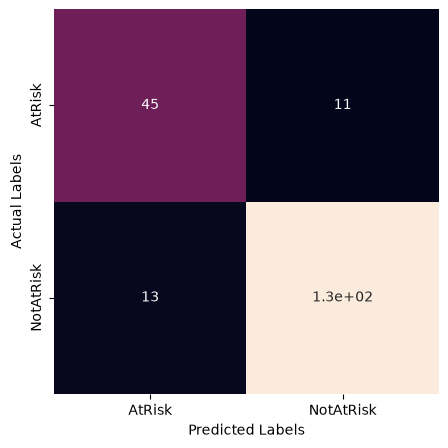

In [ ]:
# Compute the one-component media representation.
sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

# Remove fields that reveal the outcome directly.
sd_XX.drop(columns=['student_key', 'exam_result', 'grade'], inplace=True)

# Retain the stratified holdout split.
X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43, stratify=sd_y
)

# Apply the existing supervised bin boundaries.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 4, 5, 6], 'ccp_alpha': [0.0, 0.005, 0.01]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)
X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)

# Prepare categorical inputs for the estimator.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=5, m_neighbors=10)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Standardize features using training-derived parameters.
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=cat_cols)
X_test = pd.DataFrame(scaler.transform(X_test), columns=cat_cols)

# Use the established encoding for categorical values or labels.
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
# Calculate the configured statistical comparison.
y_train = pd.Series(y_train_encoded)
y_test = pd.Series(y_test_encoded)


# Select the model-ranked input subset.
xgb_selector = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=43
)

sfm = SelectFromModel(estimator=xgb_selector, threshold='median')
X_train_selected = sfm.fit_transform(X_train, y_train)
X_test_selected = sfm.transform(X_test)
selected_features = [cat_cols[i] for i in sfm.get_support(indices=True)]
print(f"{len(selected_features)} features were selected by XGBoost using embedded feature selection:\n{selected_features}")
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)

# Fit the configured bagged-tree classifier.
clf = RandomForestClassifier(n_estimators=100, random_state=43)
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'max_features': ['sqrt', 0.5, 0.7],
    'min_samples_split': [3, 5, 7, 9],
    'min_samples_leaf': [2, 4, 6],
    'bootstrap': [True, False]
}
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)
random_search = RandomizedSearchCV(
    clf,
    param_distributions=param_dist,
    n_iter=300,
    cv=stratified_cv,
    verbose=1,
    random_state=43,
    n_jobs=-1
)
random_search.fit(X_train, y_train)

# Evaluation.
print(f'Best parameters found: {random_search.best_params_}')
best_clf_rf = random_search.best_estimator_

ad.summarize_stratified_cv(X_train, y_train, best_clf_rf, cv_=5, print_dict=False)
y_pred_encoded = best_clf_rf.predict(X_test)
y_pred = label_encoder.inverse_transform(y_pred_encoded)
y_test = label_encoder.inverse_transform(y_test)

print(ad.classification_report(y_test, y_pred))
ad.save_confusion_heatmap(y_test, y_pred, "confusion_matrix_rf")

In [8]:
from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt

# Choose one tree from the forest.
best_clf_rf_tree = best_clf_rf.estimators_[1]

depth = best_clf_rf_tree.get_depth()
n_leaves = best_clf_rf_tree.get_n_leaves()

print(f"The selected decision tree has a depth of {depth} and {n_leaves} leaves.")

The selected decision tree has a depth of 6 and 30 leaves.


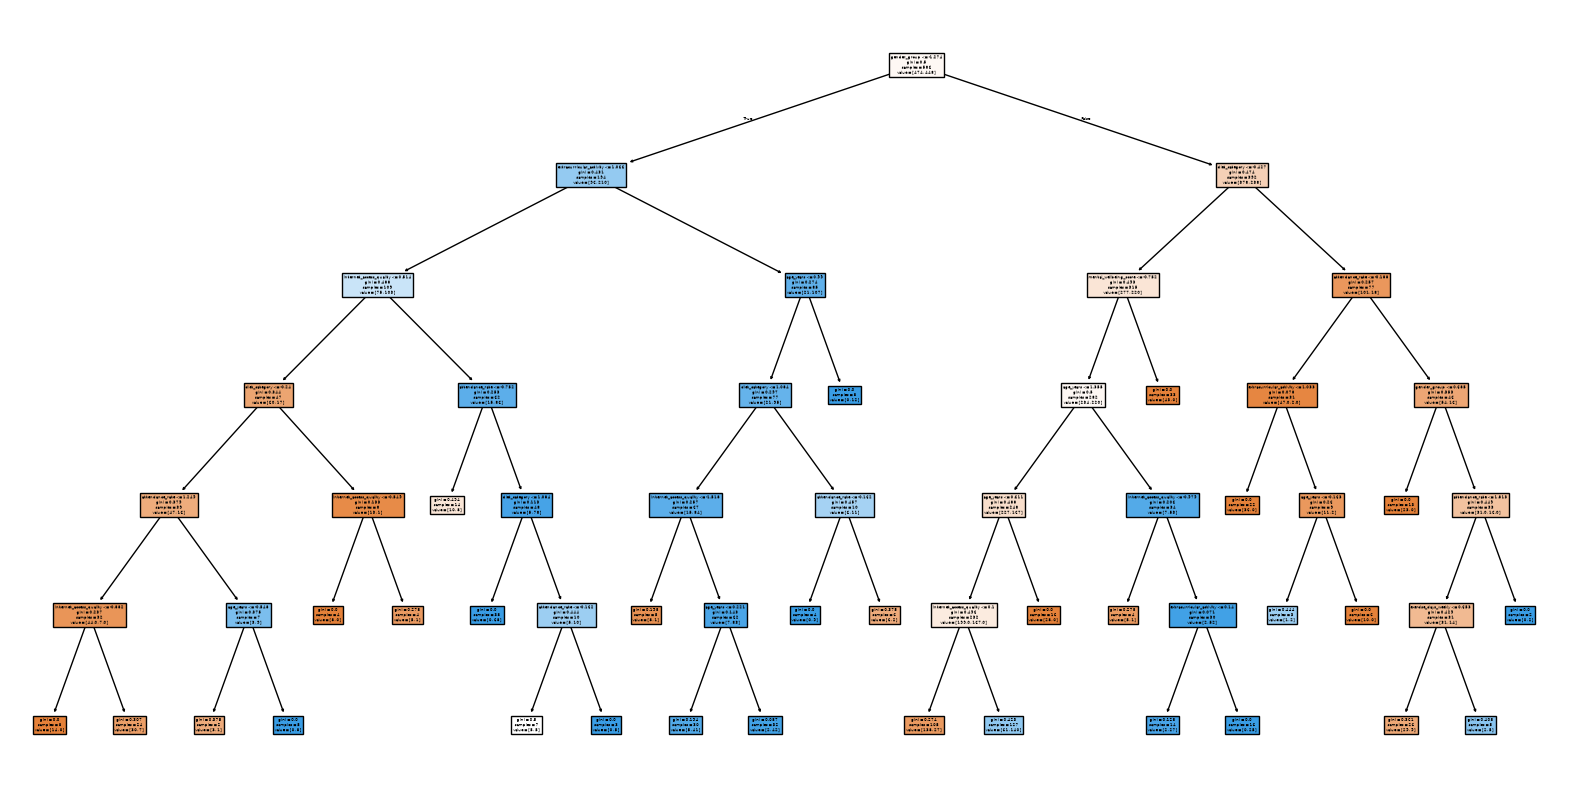

In [9]:
plt.figure(figsize=(20, 10))
plot_tree(best_clf_rf_tree, feature_names=cat_cols, filled=True, rounded=False)
plt.savefig("img/decision_tree_rf.png", bbox_inches='tight')  # Configure the chart layout.
plt.show()

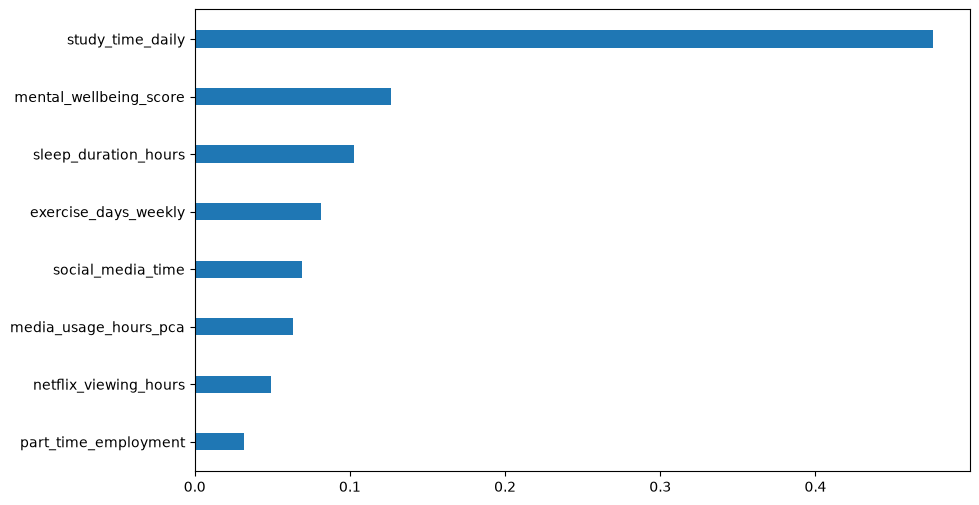

Feature importances (descending order):
study_time_daily: 0.4756
mental_wellbeing_score: 0.1267
sleep_duration_hours: 0.1024
exercise_days_weekly: 0.0817
social_media_time: 0.0694
media_usage_hours_pca: 0.0636
netflix_viewing_hours: 0.0489
part_time_employment: 0.0317


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Search the hyperparameter candidates.
best_clf_rf = random_search.best_estimator_

# Get feature importances from the trained randomforest model.
importances = best_clf_rf.feature_importances_

# Get the feature names already selected.
selected_featuress = X_train.columns  # X_train already has selected features!.

# Sort the feature importances in descending order.
indices = np.argsort(importances)[::-1]

# Render the current analysis view.
plt.figure(figsize=(10, 6))
# Plt.title("feature importance").
plt.barh(range(len(selected_featuress)), importances[indices], align="center", height=0.3)  # Adjust the bar thickness here.
plt.yticks(range(len(selected_featuress)), selected_featuress[indices])
plt.gca().invert_yaxis()  # Invert the y-axis to have the most important feature at the top.
plt.savefig('img/feature_importance_rf.png', dpi=300, bbox_inches='tight')
plt.show()

print("Feature importances (descending order):")
for i in indices:
    print(f"{selected_featuress[i]}: {importances[i]:.4f}")

## Gradient-boosted trees (XGBoost)

Repeat the feature preparation and hyperparameter search with XGBoost. The comparison uses the same held-out partition and target encoding; predictions are decoded into the class names for the printed report.


8 features were selected by XGBoost using embedded feature selection:
['exercise_days_weekly', 'mental_wellbeing_score', 'netflix_viewing_hours', 'part_time_employment', 'sleep_duration_hours', 'social_media_time', 'study_time_daily', 'media_usage_hours_pca']
Fitting 5 folds for each of 500 candidates, totalling 2500 fits
Best parameters found: {'subsample': 0.6, 'reg_lambda': 5, 'reg_alpha': 0.01, 'n_estimators': np.int64(600), 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 0.7}
Mean Accuracy is 94.62 +/- 0.52
Mean Precision is 94.68 +/- 0.55
Mean Recall is 94.62 +/- 0.52
Mean F-score is 94.62 +/- 0.52
              precision    recall  f1-score   support

      AtRisk       0.82      0.82      0.82        56
   NotAtRisk       0.93      0.93      0.93       144

    accuracy                           0.90       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.90      0.90      0.90       200



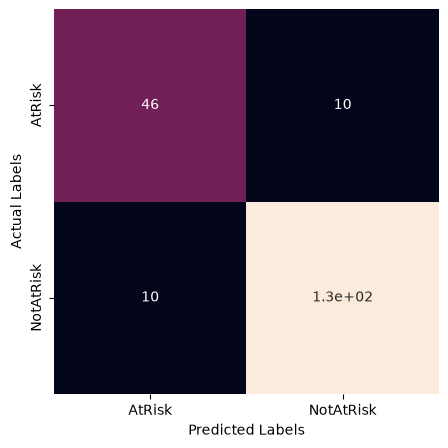

In [ ]:
# Compute the one-component media representation.
sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

# Remove fields that reveal the outcome directly.
sd_XX.drop(columns=['student_key', 'exam_result', 'grade'], inplace=True)

# Retain the stratified holdout split.
X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43, stratify=sd_y
)

# Apply the existing supervised bin boundaries.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 4, 5, 6], 'ccp_alpha': [0.0, 0.005, 0.01]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)
X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)

# Prepare categorical inputs for the estimator.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=5, m_neighbors=10)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Standardize features using training-derived parameters.
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=cat_cols)
X_test = pd.DataFrame(scaler.transform(X_test), columns=cat_cols)

# Use the established encoding for categorical values or labels.
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
# Calculate the configured statistical comparison.
y_train = pd.Series(y_train_encoded)
y_test = pd.Series(y_test_encoded)


# Select the model-ranked input subset.
X_train_selected = sfm.fit_transform(X_train, y_train)
X_test_selected = sfm.transform(X_test)
selected_features = [cat_cols[i] for i in sfm.get_support(indices=True)]
print(f"{len(selected_features)} features were selected by XGBoost using embedded feature selection:\n{selected_features}")
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)

# Fit the configured boosted-tree classifier.
clf = XGBClassifier(
    random_state=43,
    eval_metric='logloss',
)

# Fit the configured boosted-tree classifier.
param_dist = {
    'n_estimators': np.arange(100, 701, 100),  # Reduce upper limit to avoid too many trees.
    'max_depth': [3, 4, 5, 6, 7],              # Shallow trees generalize better.
    'learning_rate': [0.01, 0.05, 0.1],        # Smaller values for smoother learning.
    'subsample': [0.6, 0.7, 0.8],              # Avoid overfitting by using row sampling.
    'colsample_bytree': [0.6, 0.7, 0.8],       # Avoid overfitting by using feature sampling.
    'gamma': [0.1, 0.3, 0.5, 1],               # Minimum gain needed to split a node (adds pruning).
    'min_child_weight': [3, 5, 7],             # Minimum sum of instance weight in a child (larger = more conservative).
    'reg_alpha': [0.01, 0.1, 1],               # L1 regularization.
    'reg_lambda': [1, 2, 5]                    # L2 regularization.
}


# Summarize results over the established validation folds.
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)

# Search the hyperparameter candidates.
random_search = RandomizedSearchCV(
    clf, param_distributions=param_dist, 
    n_iter=500, 
    cv=stratified_cv, 
    verbose=1, 
    random_state=43, 
    n_jobs=-1
)

# Evaluation.
random_search.fit(X_train, y_train)
# Print best hyperparameters.
print(f'Best parameters found: {random_search.best_params_}')

best_clf_xgb = random_search.best_estimator_
ad.summarize_stratified_cv(X_train, y_train, best_clf_xgb, cv_=5, print_dict=False)
y_pred = best_clf_xgb.predict(X_test)

# Keep the target categories consistent across splits.
y_pred = label_encoder.inverse_transform(y_pred)
y_test = label_encoder.inverse_transform(y_test)

# Compare actual and predicted class frequencies.
print(ad.classification_report(y_test, y_pred))
ad.save_confusion_heatmap(y_test, y_pred, "confusion_matrix_xgb")

In [12]:
from xgboost import Booster

booster = best_clf_xgb.get_booster()
model_dump = booster.get_dump(with_stats=True)
tree = model_dump[1].split('\n')
depth = max(line.count('\t') for line in tree if line.strip() != '')
n_leaves = sum(1 for line in tree if 'leaf=' in line)
print(f"The first XGBoost tree has a depth of {depth} and {n_leaves} leaves.")

The first XGBoost tree has a depth of 6 and 12 leaves.


<Figure size 2000x2400 with 0 Axes>

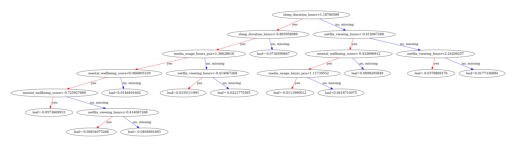

In [13]:
# Fit the configured boosted-tree classifier.
import matplotlib.pyplot as plt
from xgboost import plot_tree

plt.figure(figsize=(20, 24))  # Render the current analysis view.

# Fit the configured boosted-tree classifier.
plot_tree(best_clf_xgb, num_trees=1, rankdir='TB')  # You can adjust the num_trees parameter as needed.

# Render the current analysis view.
plt.savefig('img/decision_tree_plot.png', dpi=300, bbox_inches='tight')

# Render the current analysis view.
plt.show()

<Figure size 1200x1600 with 0 Axes>

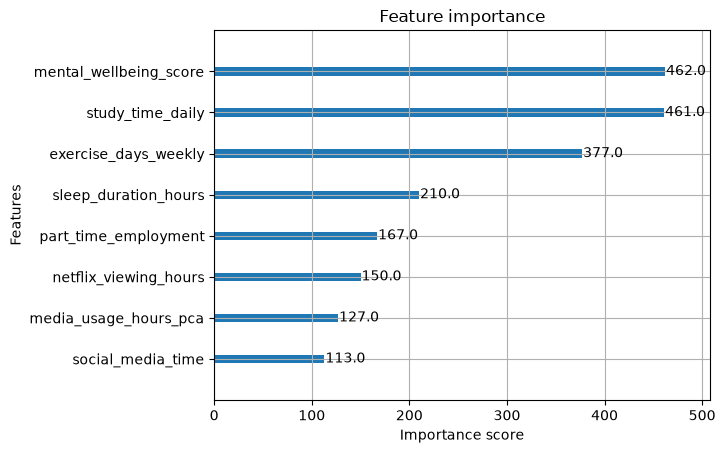

mental_wellbeing_score: 462.0
study_time_daily: 461.0
exercise_days_weekly: 377.0
sleep_duration_hours: 210.0
part_time_employment: 167.0
netflix_viewing_hours: 150.0
media_usage_hours_pca: 127.0
social_media_time: 113.0


In [14]:
import matplotlib.pyplot as plt
import xgboost as xgb

# Render the current analysis view.
plt.figure(figsize=(12,16))  # Adjust the size as needed.
xgb.plot_importance(best_clf_xgb, importance_type='weight', max_num_features=14)

# Render the current analysis view.
plt.savefig('img/feature_importance_xgb.png', dpi=300, bbox_inches='tight')
plt.show()

# Report the configured model or statistical measure.
importance_dict = booster.get_score(importance_type='weight')

# Sort features by importance descending.
sorted_features = sorted(importance_dict.items(), key=lambda x: x[1], reverse=True)

# Print("feature importances (descending order):").
for feature, score in sorted_features:
    print(f"{feature}: {score}")

## Discrimination across thresholds

The final cell draws ROC curves from the stored class probabilities. ROC–AUC describes ranking discrimination across thresholds, not the fraction of correct predictions at one threshold. Read it alongside the confusion matrices and minority-class recall.


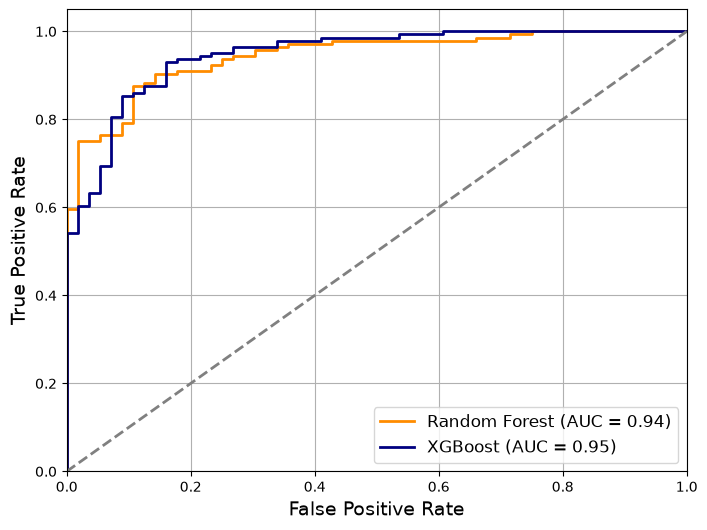

In [15]:
from sklearn.metrics import roc_curve, auc

# Get probability predictions for positive class.
y_score_rf = best_clf_rf.predict_proba(X_test)[:, 1]
y_score_xgb = best_clf_xgb.predict_proba(X_test)[:, 1]

# Display class discrimination across decision thresholds.
fpr_rf, tpr_rf, _ = roc_curve(y_test_encoded, y_score_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test_encoded, y_score_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Display class discrimination across decision thresholds.
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')
plt.plot(fpr_xgb, tpr_xgb, color='navy', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
# Display class discrimination across decision thresholds.
plt.legend(loc='lower right', fontsize=12)
plt.grid(True)
plt.savefig("img/roc_curve.png")
plt.show()

## Closing interpretation

Compare Random Forest and XGBoost using the printed per-class metrics, confusion matrices and ROC curves. Report cross-validation statistics separately from the held-out 200-record evaluation. The underlying data are synthetic; high performance on this split does not establish prospective early-warning utility.

**Methodological note:** some learned preprocessing steps are fitted before the search folds, which can inflate cross-validation estimates. A future production-grade study should nest those transformations inside the training folds and validate on independent real cohorts. The computational sequence is intentionally preserved here.
